# Fase 5 (CRISP-DM): Evaluación en Prueba, Desglose por Perfil Operativo
 
**Metodología:** CRISP-DM — Fase 5 (*Evaluation*)  
**Entradas:** `data/03_processed/train_final.parquet`, `data/03_processed/test_final.parquet`, `data/01_raw/test-00000-of-00001.parquet`, `models/best_eta_model.joblib`, `models/preprocessor_reg.joblib`  


## 1. Carga de Artefactos y Modelos Comparativos de Referencia

Se cargan los datos finales de entrenamiento y prueba junto con `models/best_eta_model.joblib` y se reconstruyen sobre las mismas particiones los comparadores exactos de **Nivel 1 (Baseline)**, **Nivel 2 (Feature Engineering Estándar)** y **Nivel 2 Tuned** (mismos hiperparámetros globales que el modelo ganador, pero **sin** características de clustering ni sub-modelos especializados).

In [1]:
from __future__ import annotations

from pathlib import Path
from typing import Any

import scipy.stats as stats  # prevenir bloqueos DLL en Windows antes de sklearn
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    median_absolute_error,
    r2_score,
    root_mean_squared_error,
)
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
sns.set_style('whitegrid')

ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RANDOM_STATE = 42
TARGET_COL = "Time_taken (min)"
_DEFAULT_MODELS_DIR = ROOT_DIR / "models"

CLUSTER_NAMES: dict[int, str] = {
    0: "Express urbano matutino",
    1: "Operación estándar nocturna",
    2: "Cuello de botella operativo",
}

COLS_NIVEL_1: list[str] = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude",
    "Vehicle_condition",
    "multiple_deliveries",
    "Road_traffic_density",
    "Festival_Yes",
    "City_ord",
    "City_Semi-Urban",
    "City_Urban",
    "City_Unknown",
    "Weather_conditions",
    "Weather_Cloudy",
    "Weather_Fog",
    "Weather_Sandstorms",
    "Weather_Stormy",
    "Weather_Windy",
    "Type_of_order_Drinks",
    "Type_of_order_Meal",
    "Type_of_order_Snack",
    "Type_of_vehicle_motorcycle",
    "Type_of_vehicle_scooter",
    "Type_of_vehicle_electric_scooter",
]

COLS_NIVEL_2: list[str] = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "dist_haversine_km",
    "dist_manhattan_km",
    "Tiempo_preparacion_min",
    "dia_semana",
    "es_fin_semana",
    "hora_pedido",
    "hora_sin",
    "hora_cos",
    "Franja_Manana",
    "Franja_Almuerzo_Pico",
    "Franja_Tarde_Valle",
    "Franja_Cena_Pico",
    "Vehicle_condition",
    "multiple_deliveries",
    "Road_traffic_density",
    "Festival_Yes",
    "City_ord",
    "City_Semi-Urban",
    "City_Urban",
    "City_Unknown",
    "Weather_conditions",
    "Weather_Cloudy",
    "Weather_Fog",
    "Weather_Sandstorms",
    "Weather_Stormy",
    "Weather_Windy",
    "Type_of_order_Drinks",
    "Type_of_order_Meal",
    "Type_of_order_Snack",
    "Type_of_vehicle_motorcycle",
    "Type_of_vehicle_scooter",
    "Type_of_vehicle_electric_scooter",
]

CLUSTER_FEATURE_COLS: list[str] = [
    "cluster_label",
    "dist_centroide_1",
    "dist_centroide_2",
    "dist_centroide_3",
    "prob_pertenencia_1",
    "prob_pertenencia_2",
    "prob_pertenencia_3",
]

COLS_NIVEL_3: list[str] = COLS_NIVEL_2 + CLUSTER_FEATURE_COLS

CONTINUOUS_SCALE_COLS: list[str] = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "dist_haversine_km",
    "dist_manhattan_km",
    "Tiempo_preparacion_min",
    "dia_semana",
    "hora_pedido",
    "hora_sin",
    "hora_cos",
    "dist_centroide_1",
    "dist_centroide_2",
    "dist_centroide_3",
    "prob_pertenencia_1",
    "prob_pertenencia_2",
    "prob_pertenencia_3",
]


def get_feature_cols(df: pd.DataFrame, level: int = 3) -> list[str]:
    """Devuelve las columnas presentes en `df` correspondientes al nivel de ablación."""
    mapping = {1: COLS_NIVEL_1, 2: COLS_NIVEL_2, 3: COLS_NIVEL_3}
    if level not in mapping:
        raise ValueError(f"Nivel inválido: {level}. Use 1, 2 o 3.")
    return [col for col in mapping[level] if col in df.columns]


def build_regression_preprocessor(feature_cols: list[str] | None = None) -> ColumnTransformer:
    """Construye un `ColumnTransformer` reproducible para las variables de regresión."""
    cols = list(feature_cols) if feature_cols is not None else list(COLS_NIVEL_3)
    scale_cols = [c for c in CONTINUOUS_SCALE_COLS if c in cols]
    pass_cols = [c for c in cols if c not in scale_cols]

    transformers = []
    if scale_cols:
        transformers.append(("num_scaler", StandardScaler(), scale_cols))
    if pass_cols:
        transformers.append(("pass_features", "passthrough", pass_cols))

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        verbose_feature_names_out=False,
    )


def save_preprocessor(
    preprocessor: ColumnTransformer, path: str | Path | None = None
) -> Path:
    """Serializa el `ColumnTransformer` en `models/preprocessor_reg.joblib`."""
    target_path = (
        _DEFAULT_MODELS_DIR / "preprocessor_reg.joblib" if path is None else Path(path)
    )
    target_path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(preprocessor, target_path)
    return target_path


class ClusterSpecializedHybridRegressor(BaseEstimator, RegressorMixin):
    """Regresor híbrido (Estrategia A + C): combina modelo global y especialistas por cluster.

    El componente global opera sobre las variables limpias y de ingeniería (`global_cols`)
    para evitar degradar particiones ortogonales por redundancia radial, mientras que los
    sub-modelos especializados aprenden la superficie no lineal específica dentro de cada
    régimen operativo (`cluster_label`) utilizando además las distancias continuas a los
    centroides y probabilidades de pertenencia (`cluster_cols`).
    """

    def __init__(
        self,
        global_params: dict[str, Any] | None = None,
        cluster_params: dict[str, Any] | None = None,
        global_weight: float = 0.70,
        cluster_col: str = "cluster_label",
        global_cols: list[str] | None = None,
        cluster_cols: list[str] | None = None,
        random_state: int = RANDOM_STATE,
    ) -> None:
        self.global_params = global_params
        self.cluster_params = cluster_params
        self.global_weight = float(global_weight)
        self.cluster_col = cluster_col
        self.global_cols = global_cols
        self.cluster_cols = cluster_cols
        self.random_state = int(random_state)

    def _resolve_params(self) -> tuple[dict[str, Any], dict[str, Any]]:
        default_global = {
            "max_iter": 300,
            "max_depth": 10,
            "max_leaf_nodes": 25,
            "min_samples_leaf": 60,
            "learning_rate": 0.05,
            "l2_regularization": 2.0,
            "random_state": self.random_state,
        }
        default_cluster = {
            "max_iter": 250,
            "max_depth": 8,
            "max_leaf_nodes": 20,
            "min_samples_leaf": 40,
            "learning_rate": 0.04,
            "l2_regularization": 5.0,
            "random_state": self.random_state,
        }
        g_params = {**default_global, **(self.global_params or {})}
        c_params = {**default_cluster, **(self.cluster_params or {})}
        return g_params, c_params

    def _prepare_indices(self, X: pd.DataFrame | np.ndarray) -> None:
        if isinstance(X, pd.DataFrame):
            cols = list(X.columns)
            self.feature_names_in_ = np.asarray(cols, dtype=object)
            self.n_features_in_ = len(cols)
        else:
            cols = list(self.cluster_cols or COLS_NIVEL_3)
            self.feature_names_in_ = np.asarray(cols, dtype=object)
            self.n_features_in_ = X.shape[1]

        g_target = list(self.global_cols or COLS_NIVEL_2)
        c_target = [
            c
            for c in (self.cluster_cols or COLS_NIVEL_3)
            if c != self.cluster_col
        ]

        self.global_indices_ = [cols.index(c) for c in g_target if c in cols]
        self.cluster_indices_ = [cols.index(c) for c in c_target if c in cols]
        if not self.global_indices_:
            self.global_indices_ = list(range(self.n_features_in_))
        if not self.cluster_indices_:
            self.cluster_indices_ = list(range(self.n_features_in_))
        if self.cluster_col not in cols:
            raise ValueError(
                f"La columna '{self.cluster_col}' es requerida por ClusterSpecializedHybridRegressor."
            )
        self.cluster_col_idx_ = cols.index(self.cluster_col)

    def fit(self, X: pd.DataFrame | np.ndarray, y: pd.Series | np.ndarray) -> "ClusterSpecializedHybridRegressor":
        self._prepare_indices(X)
        arr = np.asarray(X, dtype=float)
        y_arr = np.asarray(y, dtype=float)

        g_params, c_params = self._resolve_params()
        self.global_model_ = HistGradientBoostingRegressor(**g_params)
        self.global_model_.fit(arr[:, self.global_indices_], y_arr)

        clusters = np.round(arr[:, self.cluster_col_idx_]).astype(int)
        self.clusters_ = np.sort(np.unique(clusters))
        self.cluster_models_: dict[int, HistGradientBoostingRegressor] = {}

        for cluster_id in self.clusters_:
            mask = clusters == cluster_id
            model_k = HistGradientBoostingRegressor(**c_params)
            model_k.fit(arr[mask][:, self.cluster_indices_], y_arr[mask])
            self.cluster_models_[int(cluster_id)] = model_k

        return self

    def predict(self, X: pd.DataFrame | np.ndarray) -> np.ndarray:
        arr = np.asarray(X, dtype=float)
        pred_global = self.global_model_.predict(arr[:, self.global_indices_])

        clusters = np.round(arr[:, self.cluster_col_idx_]).astype(int)
        pred_cluster = pred_global.copy()

        for cluster_id, model_k in self.cluster_models_.items():
            mask = clusters == cluster_id
            if np.any(mask):
                pred_cluster[mask] = model_k.predict(arr[mask][:, self.cluster_indices_])

        w = self.global_weight
        return w * pred_global + (1.0 - w) * pred_cluster


def compute_metrics(
    y_true: np.ndarray | pd.Series, y_pred: np.ndarray | pd.Series
) -> dict[str, float]:
    """Calcula MAE, RMSE, MAPE (%), MedAE, R2 y porcentaje de errores severos (>10 min)."""
    yt = np.asarray(y_true, dtype=float)
    yp = np.asarray(y_pred, dtype=float)
    abs_err = np.abs(yt - yp)
    return {
        "MAE": float(mean_absolute_error(yt, yp)),
        "RMSE": float(root_mean_squared_error(yt, yp)),
        "MAPE_pct": float(mean_absolute_percentage_error(yt, yp) * 100.0),
        "MedAE": float(median_absolute_error(yt, yp)),
        "R2": float(r2_score(yt, yp)),
        "Error_Gt_10min_pct": float(np.mean(abs_err > 10.0) * 100.0),
        "Error_Gt_8min_pct": float(np.mean(abs_err > 8.0) * 100.0),
    }


def evaluate_by_cluster(
    df_test: pd.DataFrame,
    y_pred_lvl2: np.ndarray,
    y_pred_lvl3: np.ndarray,
    y_pred_lvl1: np.ndarray | None = None,
) -> pd.DataFrame:
    """Desglosa las métricas finales en `test` por perfil operativo (`cluster_label`)."""
    y_true = df_test[TARGET_COL].to_numpy(dtype=float)
    clusters = df_test["cluster_label"].to_numpy(dtype=int)
    rows = []

    for cluster_id in sorted(np.unique(clusters)):
        mask = clusters == cluster_id
        m3 = compute_metrics(y_true[mask], y_pred_lvl3[mask])
        m2 = compute_metrics(y_true[mask], y_pred_lvl2[mask])
        row: dict[str, Any] = {
            "Cluster": int(cluster_id),
            "Nombre_Perfil": CLUSTER_NAMES.get(int(cluster_id), f"Cluster {cluster_id}"),
            "N_Pedidos": int(np.sum(mask)),
            "Pct_Test": round(float(np.mean(mask) * 100.0), 1),
            "ETA_Real_Medio": round(float(np.mean(y_true[mask])), 2),
            "MAE_Lvl2": round(m2["MAE"], 4),
            "MAE_Lvl3": round(m3["MAE"], 4),
            "Mejora_MAE": round(m2["MAE"] - m3["MAE"], 4),
            "RMSE_Lvl3": round(m3["RMSE"], 4),
            "MAPE_Lvl3_pct": round(m3["MAPE_pct"], 2),
            "R2_Lvl3": round(m3["R2"], 4),
            "Err_Gt_10min_Lvl3_pct": round(m3["Error_Gt_10min_pct"], 2),
        }
        if y_pred_lvl1 is not None:
            m1 = compute_metrics(y_true[mask], y_pred_lvl1[mask])
            row["MAE_Lvl1"] = round(m1["MAE"], 4)
            row["Err_Gt_10min_Lvl1_pct"] = round(m1["Error_Gt_10min_pct"], 2)
        rows.append(row)

    return pd.DataFrame(rows)


def evaluate_by_courier_completeness(
    df_test: pd.DataFrame,
    raw_test_df: pd.DataFrame,
    y_pred_lvl3: np.ndarray,
    y_pred_lvl1: np.ndarray | None = None,
) -> pd.DataFrame:
    """Compara el desempeño en registros con calificación observada vs. imputada en origen."""
    y_true = df_test[TARGET_COL].to_numpy(dtype=float)
    obs_mask = raw_test_df["Delivery_person_Ratings"].notna().to_numpy()
    subsets = [
        ("Global test completo", np.ones(len(df_test), dtype=bool)),
        ("Repartidor observado en origen (no imputado)", obs_mask),
        ("Repartidor sin rating en origen (imputado)", ~obs_mask),
    ]
    rows = []
    for label, mask in subsets:
        m3 = compute_metrics(y_true[mask], y_pred_lvl3[mask])
        row: dict[str, Any] = {
            "Subconjunto": label,
            "N_Pedidos": int(np.sum(mask)),
            "Pct_Test": round(float(np.mean(mask) * 100.0), 2),
            "MAE_Lvl3": round(m3["MAE"], 4),
            "RMSE_Lvl3": round(m3["RMSE"], 4),
            "MAPE_Lvl3_pct": round(m3["MAPE_pct"], 2),
            "R2_Lvl3": round(m3["R2"], 4),
            "Err_Gt_10min_Lvl3_pct": round(m3["Error_Gt_10min_pct"], 2),
        }
        if y_pred_lvl1 is not None:
            m1 = compute_metrics(y_true[mask], y_pred_lvl1[mask])
            row["MAE_Lvl1"] = round(m1["MAE"], 4)
            row["R2_Lvl1"] = round(m1["R2"], 4)
        rows.append(row)
    return pd.DataFrame(rows)


df_train = pd.read_parquet('../data/03_processed/train_final.parquet')
df_test = pd.read_parquet('../data/03_processed/test_final.parquet')
raw_test = pd.read_parquet('../data/01_raw/test-00000-of-00001.parquet')

best_model = joblib.load('../models/best_eta_model.joblib')
preprocessor_reg = joblib.load('../models/preprocessor_reg.joblib')

cols_1 = get_feature_cols(df_train, level=1)
cols_2 = get_feature_cols(df_train, level=2)
cols_3 = get_feature_cols(df_train, level=3)

y_train = df_train[TARGET_COL]
y_test = df_test[TARGET_COL].to_numpy(dtype=float)

# Modelo Nivel 1 Baseline (parámetros base de ablación)
m_lvl1 = HistGradientBoostingRegressor(
    max_iter=300, max_depth=10, max_leaf_nodes=25, min_samples_leaf=60,
    learning_rate=0.05, l2_regularization=2.0, random_state=RANDOM_STATE,
).fit(df_train[cols_1], y_train)
pred_lvl1 = m_lvl1.predict(df_test[cols_1])

# Modelo Nivel 2 Estándar (parámetros base de ablación)
m_lvl2_base = HistGradientBoostingRegressor(
    max_iter=300, max_depth=10, max_leaf_nodes=25, min_samples_leaf=60,
    learning_rate=0.05, l2_regularization=2.0, random_state=RANDOM_STATE,
).fit(df_train[cols_2], y_train)
pred_lvl2_base = m_lvl2_base.predict(df_test[cols_2])

# Modelo Nivel 2 Tuned (comparador estrictamente pareado con los mismos hiperparámetros globales)
global_cfg = dict(best_model.global_params or {})
m_lvl2_tuned = HistGradientBoostingRegressor(
    **{**global_cfg, 'random_state': RANDOM_STATE}
).fit(df_train[cols_2], y_train)
pred_lvl2_tuned = m_lvl2_tuned.predict(df_test[cols_2])

# Predicciones finales del modelo híbrido ganador (Nivel 3 A + C)
pred_lvl3 = best_model.predict(df_test[cols_3])

print(f'Modelo híbrido cargado: global_weight={best_model.global_weight}, params={best_model.global_params}')
print(f'Sub-modelos de cluster cargados: {list(best_model.cluster_models_.keys())}')

Modelo híbrido cargado: global_weight=0.8, params={'max_iter': 350, 'max_depth': 10, 'max_leaf_nodes': 31, 'min_samples_leaf': 50, 'learning_rate': 0.04, 'l2_regularization': 3.0}
Sub-modelos de cluster cargados: [0, 1, 2]


## 2. Evaluación Final en `test` ($n = 9,117$) y Auditoría por Completitud de Origen

Se reportan las métricas `MAE`, `RMSE`, `MAPE`, `MedAE`, `R²` y tasa de errores severos (`|error| > 10 min`) sobre todo el conjunto `test` y se audita explícitamente el impacto operativo de los **361 pedidos (`3.96%`)** que llegaron sin `Delivery_person_Ratings` observado en origen.

In [2]:
reports_dir = Path('../reports')
fig_dir = reports_dir / 'figures'
fig_dir.mkdir(parents=True, exist_ok=True)

summary_rows = []
for name, pred in [
    ('Nivel 1: Baseline (Sin FE ni Clusters)', pred_lvl1),
    ('Nivel 2: Feature Engineering (Base)', pred_lvl2_base),
    ('Nivel 2: Feature Engineering (Tuned sin Clusters)', pred_lvl2_tuned),
    ('Nivel 3: Híbrido A + C (best_eta_model)', pred_lvl3),
]:
    m = compute_metrics(y_test, pred)
    summary_rows.append({
        'Modelo': name,
        'MAE_min': round(m['MAE'], 4),
        'RMSE_min': round(m['RMSE'], 4),
        'MAPE_pct': round(m['MAPE_pct'], 2),
        'MedAE_min': round(m['MedAE'], 4),
        'R2': round(m['R2'], 4),
        'Err_Gt_10min_pct': round(m['Error_Gt_10min_pct'], 2),
        'Err_Gt_8min_pct': round(m['Error_Gt_8min_pct'], 2),
    })

df_summary = pd.DataFrame(summary_rows)
df_summary.to_csv(reports_dir / 'evaluacion_resumen_test.csv', index=False)
print('=== Resumen Comparativo Global en Test (n = 9,117) ===')
display(df_summary)

df_completeness = evaluate_by_courier_completeness(
    df_test, raw_test, y_pred_lvl3=pred_lvl3, y_pred_lvl1=pred_lvl1
)
print('\n=== Auditoría por Completitud del Repartidor en Origen ===')
display(df_completeness)

sev1 = df_summary.loc[0, 'Err_Gt_10min_pct']
sev3 = df_summary.loc[3, 'Err_Gt_10min_pct']
print(
    f'Reducción relativa de errores severos (>10 min) frente al Baseline Nivel 1: '
    f'{sev1:.2f}% -> {sev3:.2f}% (-{(sev1 - sev3) / sev1 * 100:.1f}%)'
)

=== Resumen Comparativo Global en Test (n = 9,117) ===


,Modelo,MAE_min,RMSE_min,MAPE_pct,MedAE_min,R2,Err_Gt_10min_pct,Err_Gt_8min_pct
0,Nivel 1: Baseline (Sin FE ni Clusters),3.6086,4.5562,15.84,3.0408,0.7642,3.10,7.31
1,Nivel 2: Feature Engineering (Base),3.1066,3.9077,13.57,2.6638,0.8266,1.13,3.38
2,Nivel 2: Feature Engineering (Tuned sin Clusters),3.0879,3.8787,13.47,2.6504,0.8291,1.10,3.46
3,Nivel 3: Híbrido A + C (best_eta_model),3.0837,3.8728,13.46,2.6428,0.8296,1.05,3.37



=== Auditoría por Completitud del Repartidor en Origen ===


,Subconjunto,N_Pedidos,Pct_Test,MAE_Lvl3,RMSE_Lvl3,MAPE_Lvl3_pct,R2_Lvl3,Err_Gt_10min_Lvl3_pct,MAE_Lvl1,R2_Lvl1
0,Global test completo,9117,100.00,3.0837,3.8728,13.46,0.8296,1.05,3.6086,0.7642
1,Repartidor observado en origen (no imputado),8756,96.04,3.0031,3.7282,13.12,0.8418,0.67,3.5353,0.7771
2,Repartidor sin rating en origen (imputado),361,3.96,5.0377,6.4546,21.72,0.5493,10.25,5.3869,0.4676


Reducción relativa de errores severos (>10 min) frente al Baseline Nivel 1: 3.10% -> 1.05% (-66.1%)


## 3. Desglose de Métricas por Cluster Operativo y Análisis de Errores Graves ($> 8$ min)

Evaluamos la precisión del modelo híbrido dentro de cada uno de los tres regímenes operativos descubiertos en la Fase 4.1 (`Express urbano matutino`, `Operación estándar nocturna` y `Cuello de botella operativo`), e investigamos bajo qué condiciones persisten desviaciones mayores a `8 minutos`.

In [3]:
df_clusters = evaluate_by_cluster(
    df_test, y_pred_lvl2=pred_lvl2_tuned, y_pred_lvl3=pred_lvl3, y_pred_lvl1=pred_lvl1
)
df_clusters.to_csv(reports_dir / 'evaluacion_por_cluster.csv', index=False)
print('=== Desempeño en Test Desglosado por Cluster Operativo ===')
display(df_clusters)

# Análisis de errores mayores a 8 minutos
abs_err = np.abs(y_test - pred_lvl3)
mask_err8 = abs_err > 8.0
print(f'\nPedidos con |error| > 8 min: {int(mask_err8.sum())} de {len(df_test)} ({mask_err8.mean() * 100:.2f}%)')

audit_factors = pd.DataFrame({
    'Factor': [
        'Tasa global en test',
        'Festival_Yes == 1',
        'City_Semi-Urban == 1',
        'Weather_Fog == 1 o Weather_Cloudy == 1',
        'multiple_deliveries >= 2',
        'Road_traffic_density == 4 (Jam)',
        'Sin Rating de repartidor en origen',
    ],
    'N_Pedidos': [
        len(df_test),
        int((df_test['Festival_Yes'] == 1).sum()),
        int((df_test['City_Semi-Urban'] == 1).sum()),
        int(((df_test['Weather_Fog'] == 1) | (df_test['Weather_Cloudy'] == 1)).sum()),
        int((df_test['multiple_deliveries'] >= 2).sum()),
        int((df_test['Road_traffic_density'] == 4).sum()),
        int(raw_test['Delivery_person_Ratings'].isna().sum()),
    ],
    'Pct_Err_Gt_8min': [
        round(float(mask_err8.mean() * 100), 2),
        round(float(mask_err8[df_test['Festival_Yes'] == 1].mean() * 100), 2),
        round(float(mask_err8[df_test['City_Semi-Urban'] == 1].mean() * 100), 2),
        round(float(mask_err8[(df_test['Weather_Fog'] == 1) | (df_test['Weather_Cloudy'] == 1)].mean() * 100), 2),
        round(float(mask_err8[df_test['multiple_deliveries'] >= 2].mean() * 100), 2),
        round(float(mask_err8[df_test['Road_traffic_density'] == 4].mean() * 100), 2),
        round(float(mask_err8[raw_test['Delivery_person_Ratings'].isna().to_numpy()].mean() * 100), 2),
    ],
    'MAE_Grupo_min': [
        round(float(abs_err.mean()), 2),
        round(float(abs_err[df_test['Festival_Yes'] == 1].mean()), 2),
        round(float(abs_err[df_test['City_Semi-Urban'] == 1].mean()), 2),
        round(float(abs_err[(df_test['Weather_Fog'] == 1) | (df_test['Weather_Cloudy'] == 1)].mean()), 2),
        round(float(abs_err[df_test['multiple_deliveries'] >= 2].mean()), 2),
        round(float(abs_err[df_test['Road_traffic_density'] == 4].mean()), 2),
        round(float(abs_err[raw_test['Delivery_person_Ratings'].isna().to_numpy()].mean()), 2),
    ],
})
display(audit_factors)

=== Desempeño en Test Desglosado por Cluster Operativo ===


,Cluster,Nombre_Perfil,N_Pedidos,Pct_Test,ETA_Real_Medio,MAE_Lvl2,MAE_Lvl3,Mejora_MAE,RMSE_Lvl3,MAPE_Lvl3_pct,R2_Lvl3,Err_Gt_10min_Lvl3_pct,MAE_Lvl1,Err_Gt_10min_Lvl1_pct
0,0,Express urbano matutino,1760,19.3,21.31,2.8041,2.7978,0.0063,3.5639,14.51,0.7303,1.19,3.0728,1.14
1,1,Operación estándar nocturna,5857,64.2,25.43,3.2090,3.2053,0.0038,4.0144,14.36,0.8020,1.16,3.8864,4.23
2,2,Cuello de botella operativo,1500,16.5,35.50,2.9478,2.9443,0.0034,3.6519,8.72,0.7053,0.47,3.1527,1.00



Pedidos con |error| > 8 min: 307 de 9117 (3.37%)


,Factor,N_Pedidos,Pct_Err_Gt_8min,MAE_Grupo_min
0,Tasa global en test,9117,3.37,3.08
1,Festival_Yes == 1,173,1.16,2.89
2,City_Semi-Urban == 1,42,2.38,2.88
3,Weather_Fog == 1 o Weather_Cloudy == 1,3139,2.55,2.87
4,multiple_deliveries >= 2,479,1.46,2.67
5,Road_traffic_density == 4 (Jam),2890,4.05,3.42
6,Sin Rating de repartidor en origen,361,20.22,5.04


## 4. Diagnóstico Visual de Residuos

Se exporta `reports/figures/fase_05_diagnostico_residuos.png` con tres vistas diagnósticas:
1. **Real vs. Predicho** coloreado por perfil operativo (`cluster_label`) con banda de tolerancia $\pm 5\text{ min}$.
2. **Distribución de residuos ($y - \hat{y}$)** comparando la reducción de colas frente al Baseline Nivel 1.
3. **Distribución de error absoluto por Cluster y Densidad de Tráfico**.

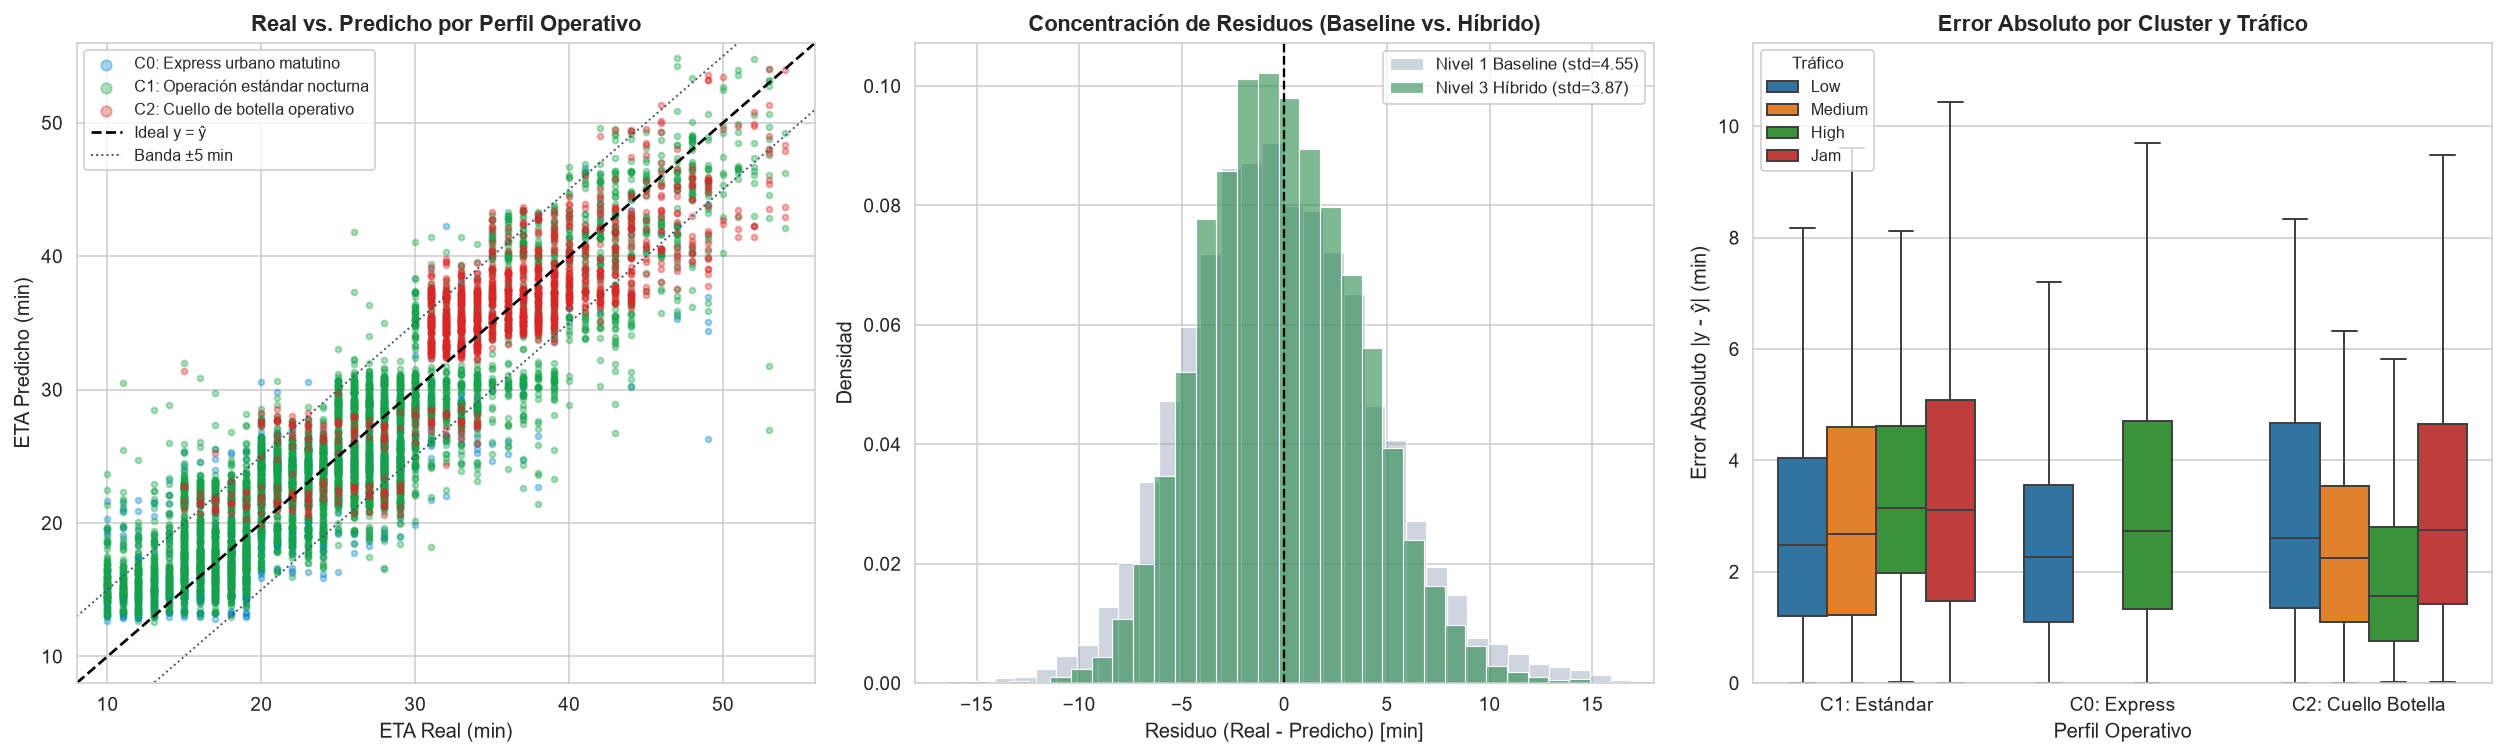

Figura guardada en: ..\reports\figures\fase_05_diagnostico_residuos.png


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=140)
cluster_palette = {0: '#0284c7', 1: '#16a34a', 2: '#dc2626'}

# Panel 1: Real vs Predicho por Cluster
for cid in [0, 1, 2]:
    m_c = df_test['cluster_label'].to_numpy() == cid
    axes[0].scatter(
        y_test[m_c], pred_lvl3[m_c],
        s=9, alpha=0.35, color=cluster_palette[cid],
        label=f'C{cid}: {CLUSTER_NAMES[cid]}',
    )
lims = [8, 56]
axes[0].plot(lims, lims, 'k--', lw=1.4, label='Ideal y = ŷ')
axes[0].plot(lims, [v + 5 for v in lims], color='#475569', ls=':', lw=1.0, label='Banda ±5 min')
axes[0].plot(lims, [v - 5 for v in lims], color='#475569', ls=':', lw=1.0)
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_xlabel('ETA Real (min)', fontsize=10.5)
axes[0].set_ylabel('ETA Predicho (min)', fontsize=10.5)
axes[0].set_title('Real vs. Predicho por Perfil Operativo', fontsize=11.5, fontweight='bold')
axes[0].legend(fontsize=8, loc='upper left', markerscale=1.8)

# Panel 2: Distribución de residuos Nivel 1 vs Nivel 3 Híbrido
res_1 = y_test - pred_lvl1
res_3 = y_test - pred_lvl3
sns.histplot(res_1, bins=45, stat='density', color='#94a3b8', alpha=0.45, label=f'Nivel 1 Baseline (std={res_1.std():.2f})', ax=axes[1])
sns.histplot(res_3, bins=45, stat='density', color='#15803d', alpha=0.55, label=f'Nivel 3 Híbrido (std={res_3.std():.2f})', ax=axes[1])
axes[1].axvline(0, color='black', ls='--', lw=1.2)
axes[1].set_xlim(-18, 18)
axes[1].set_xlabel('Residuo (Real - Predicho) [min]', fontsize=10.5)
axes[1].set_ylabel('Densidad', fontsize=10.5)
axes[1].set_title('Concentración de Residuos (Baseline vs. Híbrido)', fontsize=11.5, fontweight='bold')
axes[1].legend(fontsize=8.5)

# Panel 3: Error absoluto por Cluster y Densidad de Tráfico
df_err_plot = pd.DataFrame({
    'Error_Abs_min': abs_err,
    'Cluster': df_test['cluster_label'].map({0: 'C0: Express', 1: 'C1: Estándar', 2: 'C2: Cuello Botella'}),
    'Trafico': df_test['Road_traffic_density'].map({1: 'Low', 2: 'Medium', 3: 'High', 4: 'Jam'}),
})
sns.boxplot(
    data=df_err_plot,
    x='Cluster',
    y='Error_Abs_min',
    hue='Trafico',
    hue_order=['Low', 'Medium', 'High', 'Jam'],
    showfliers=False,
    ax=axes[2],
)
axes[2].set_ylim(0, 11.5)
axes[2].set_xlabel('Perfil Operativo', fontsize=10.5)
axes[2].set_ylabel('Error Absoluto |y - ŷ| (min)', fontsize=10.5)
axes[2].set_title('Error Absoluto por Cluster y Tráfico', fontsize=11.5, fontweight='bold')
axes[2].legend(title='Tráfico', fontsize=8, title_fontsize=8.5, loc='upper left')

plt.tight_layout()
res_fig_path = fig_dir / 'fase_05_diagnostico_residuos.png'
plt.savefig(res_fig_path, bbox_inches='tight')
plt.show()
print(f'Figura guardada en: {res_fig_path}')